=== Базовий аналіз ===
Розмір: (20, 5)
Типи даних:
 color       str
size        str
act         str
age         str
inflated    str
dtype: object
Пропущені значення: 0
Дублікати: 4

=== Співвідношення класів ===
target
0    0.6
1    0.4
Name: proportion, dtype: float64


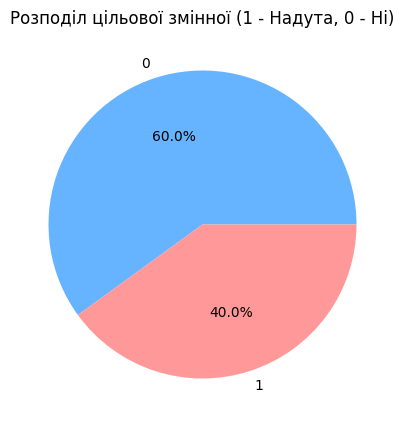


=== Розміри вибірок ===
X_train: (16, 4) | y_train (позитивних): 6
X_test : (4, 4) | y_test (позитивних): 2


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

columns = ['color', 'size', 'act', 'age', 'inflated']
df = pd.read_csv(r"C:\Users\UserComp\Downloads\balloons\adult+stretch.data", names=columns)

# Початковий аналіз
print("=== Базовий аналіз ===")
print("Розмір:", df.shape)
print("Типи даних:\n", df.dtypes)
print("Пропущені значення:", df.isnull().sum().sum())
print("Дублікати:", df.duplicated().sum())

# Кодування цільової змінної у бінарний формат (1 - T, 0 - F)
df['target'] = df['inflated'].map({'T': 1, 'F': 0})

print("\n=== Співвідношення класів ===")
class_counts = df['target'].value_counts(normalize=True)
print(class_counts)

# Візуалізація розподілу класів
plt.figure(figsize=(5, 5))
df['target'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['#66b3ff','#ff9999'])
plt.title('Розподіл цільової змінної (1 - Надута, 0 - Ні)')
plt.ylabel('')
plt.show()

# 2. Формування вибірок
X = df.drop(columns=['inflated', 'target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    stratify=y, 
    random_state=42
)

print("\n=== Розміри вибірок ===")
print("X_train:", X_train.shape, "| y_train (позитивних):", y_train.sum())
print("X_test :", X_test.shape, "| y_test (позитивних):", y_test.sum())

In [4]:
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold

# === 3. Preprocessing Pipeline ===
cat_features = ['color', 'size', 'act', 'age']

preprocessor = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])

# Перевіримо розмірність після кодування
X_train_encoded = preprocessor.fit_transform(X_train)
print(f"Кількість ознак після кодування: {X_train_encoded.shape[1]}\n")

# === 4. Побудова Baseline ===
baseline_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy="most_frequent"))
])

# Налаштування 5-fold stratified cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Метрики для оцінювання
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

# Оцінювання baseline
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore") # Ігноруємо попередження про ділення на 0 (бо Precision буде 0)
    baseline_cv_results = cross_validate(baseline_model, X_train, y_train, cv=cv, scoring=scoring)

print("=== Результати 5-fold CV для Baseline ===")
print(f"Accuracy  : {baseline_cv_results['test_accuracy'].mean():.3f}")
print(f"Precision : {baseline_cv_results['test_precision'].mean():.3f}")
print(f"Recall    : {baseline_cv_results['test_recall'].mean():.3f}")
print(f"F1-score  : {baseline_cv_results['test_f1'].mean():.3f}")
print(f"ROC-AUC   : {baseline_cv_results['test_roc_auc'].mean():.3f}")

Кількість ознак після кодування: 8

=== Результати 5-fold CV для Baseline ===
Accuracy  : 0.633
Precision : 0.000
Recall    : 0.000
F1-score  : 0.000
ROC-AUC   : 0.500


In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
import pandas as pd

# === 5. Побудова моделей класифікації ===
# Модель 1: Logistic Regression з масштабуванням
logreg_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(random_state=42))
])

# Модель 2: GaussianNB
gnb_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GaussianNB())
])

models_clf = {
    'Logistic Regression': logreg_model,
    'GaussianNB': gnb_model
}

# Збираємо результати Baseline з попереднього кроку
results_list = [{
    'Модель': 'Baseline',
    'Accuracy': baseline_cv_results['test_accuracy'].mean(),
    'Precision': baseline_cv_results['test_precision'].mean(),
    'Recall': baseline_cv_results['test_recall'].mean(),
    'F1': baseline_cv_results['test_f1'].mean(),
    'ROC-AUC': baseline_cv_results['test_roc_auc'].mean()
}]

# Оцінюємо нові моделі
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore") # Ігноруємо можливі попередження про ділення на нуль
    for name, model in models_clf.items():
        cv_res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
        results_list.append({
            'Модель': name,
            'Accuracy': cv_res['test_accuracy'].mean(),
            'Precision': cv_res['test_precision'].mean(),
            'Recall': cv_res['test_recall'].mean(),
            'F1': cv_res['test_f1'].mean(),
            'ROC-AUC': cv_res['test_roc_auc'].mean()
        })

results_df = pd.DataFrame(results_list)
print("=== Табл. 4. Результати cross-validation ===")
# Округлюємо для красивого виводу
display(results_df.round(3)) 

# === 6. Вибір моделі та прогнозування ===
# Призначаємо логістичну регресію як фінальну модель (вона зазвичай краще працює з OneHot)
final_model = logreg_model
final_model.fit(X_train, y_train)

# Прогнозування на test set
y_pred = final_model.predict(X_test)
# Отримуємо ймовірності для позитивного класу (стовпець 1)
y_proba = final_model.predict_proba(X_test)[:, 1]

print("\n=== Прогнози на тестовій вибірці (Test Set) ===")
print("Фактичні класи (y_true) :", y_test.values)
print("Передбачені мітки (y_pred):", y_pred)
print("Ймовірності класу 1 (y_proba):", np.round(y_proba, 3))

=== Табл. 4. Результати cross-validation ===


,Модель,Accuracy,Precision,Recall,F1,ROC-AUC
0,Baseline,0.633,0.0,0.0,0.0,0.5
1,Logistic Regression,1.000,1.0,1.0,1.0,1.0
2,GaussianNB,1.000,1.0,1.0,1.0,1.0



=== Прогнози на тестовій вибірці (Test Set) ===
Фактичні класи (y_true) : [0 1 1 0]
Передбачені мітки (y_pred): [0 1 1 0]
Ймовірності класу 1 (y_proba): [0.157 0.837 0.831 0.209]


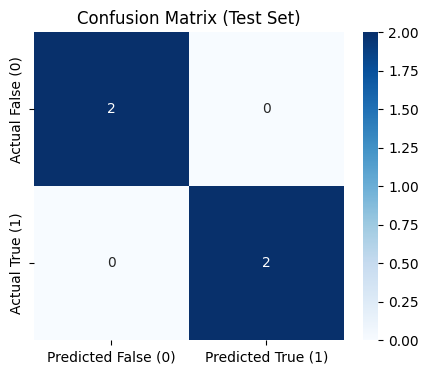

=== Аналіз Confusion Matrix ===
TN (True Negative) : 2
FP (False Positive): 0
FN (False Negative): 0
TP (True Positive) : 2

=== Метрики на Test Set ===
Accuracy  : 1.000
Precision : 1.000
Recall    : 1.000
F1-score  : 1.000
ROC-AUC   : 1.000


In [6]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import seaborn as sns
import matplotlib.pyplot as plt

# === 7. Побудова Confusion Matrix ===
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted False (0)', 'Predicted True (1)'], yticklabels=['Actual False (0)', 'Actual True (1)'])
plt.title('Confusion Matrix (Test Set)')
plt.show()

print("=== Аналіз Confusion Matrix ===")
print(f"TN (True Negative) : {tn}")
print(f"FP (False Positive): {fp}")
print(f"FN (False Negative): {fn}")
print(f"TP (True Positive) : {tp}")

# === 8. Оцінювання моделі на test set ===
acc_test = accuracy_score(y_test, y_pred)
prec_test = precision_score(y_test, y_pred)
rec_test = recall_score(y_test, y_pred)
f1_test = f1_score(y_test, y_pred)
roc_auc_test = roc_auc_score(y_test, y_proba)

print("\n=== Метрики на Test Set ===")
print(f"Accuracy  : {acc_test:.3f}")
print(f"Precision : {prec_test:.3f}")
print(f"Recall    : {rec_test:.3f}")
print(f"F1-score  : {f1_test:.3f}")
print(f"ROC-AUC   : {roc_auc_test:.3f}")

=== Вплив decision threshold ===
Threshold  | Precision  | Recall     | F1         | FP    | FN   
-----------------------------------------------------------------
0.3        | 1.000      | 1.000      | 1.000      | 0     | 0    
0.5        | 1.000      | 1.000      | 1.000      | 0     | 0    
0.7        | 1.000      | 1.000      | 1.000      | 0     | 0    


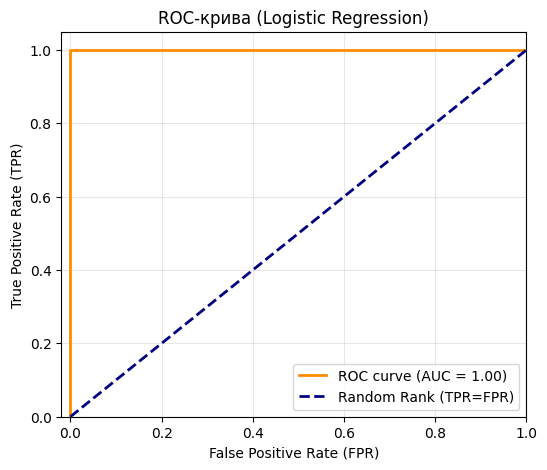

In [7]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# === 10. Дослідження decision threshold ===
thresholds = [0.3, 0.5, 0.7]
print("=== Вплив decision threshold ===")
print(f"{'Threshold':<10} | {'Precision':<10} | {'Recall':<10} | {'F1':<10} | {'FP':<5} | {'FN':<5}")
print("-" * 65)

for t in thresholds:
    # Застосовуємо новий поріг
    y_pred_t = (y_proba >= t).astype(int)
    
    # Розрахунок метрик
    cm_t = confusion_matrix(y_test, y_pred_t)
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel()
    
    prec_t = precision_score(y_test, y_pred_t, zero_division=0)
    rec_t = recall_score(y_test, y_pred_t)
    f1_t = f1_score(y_test, y_pred_t)
    
    print(f"{t:<10} | {prec_t:<10.3f} | {rec_t:<10.3f} | {f1_t:<10.3f} | {fp_t:<5} | {fn_t:<5}")


# === 11. Побудова ROC-кривої ===
fpr, tpr, roc_thresholds = roc_curve(y_test, y_proba)
roc_auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Rank (TPR=FPR)')
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC-крива (Logistic Regression)')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()